# 07 · Feature Selection and Regularisation (Ridge, LASSO)

**Syllabus:** Unit 2 (Ridge and LASSO regression). **Report items:** *Feature Selection*, *Regularization*.

Target: **log(PM2.5)**, the same as the model selected in notebook 05, so the results are directly comparable. Hyper-parameters are tuned with **time-series cross-validation on the training period only**; the test period is used once, at the end.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Ridge, Lasso, lasso_path
from sklearn.feature_selection import mutual_info_regression, SequentialFeatureSelector
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
%matplotlib inline

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

POLLUTANTS = ["PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]
df = pd.read_csv(ROOT / "data" / "processed" / "bengaluru_clean.csv", parse_dates=["Date"]).rename(columns={"PM2.5": "PM25"})
df = df.dropna(subset=["PM25"] + POLLUTANTS).sort_values("Date").reset_index(drop=True)
for s in ["Summer", "Monsoon", "Post-monsoon"]:          # Winter = reference level
    df[f"Season_{s}"] = (df["Season"] == s).astype(int)
FEATURES = POLLUTANTS + ["Season_Summer", "Season_Monsoon", "Season_Post-monsoon"]

SPLIT_DATE = pd.Timestamp(pd.read_csv(TAB / "train_test_split.csv")["SPLIT_DATE"][0])
train, test = df[df.Date < SPLIT_DATE], df[df.Date >= SPLIT_DATE]
X_tr, X_te = train[FEATURES], test[FEATURES]
y_tr, y_te = np.log(train["PM25"]), test["PM25"]

n_first_year = int((train["Date"] < train["Date"].min() + pd.DateOffset(years=1)).sum())
TS = TimeSeriesSplit(n_splits=5, test_size=(len(train) - n_first_year) // 5)   # same folds as notebook 05
print(X_tr.shape, X_te.shape)

(1181, 11) (297, 11)


# Part A: Feature selection

Three families of methods are compared:

| Family | Method | Idea |
|---|---|---|
| Filter | Pearson correlation, mutual information | Score each feature on its own, ignoring the model |
| Wrapper | Sequential forward selection | Add the feature that most improves time-series CV error, one at a time |
| Embedded | LASSO (Part B) | The L1 penalty sets weak coefficients exactly to zero during fitting |

The information-criterion search (all subsets, AIC/BIC/Cp) from notebook 05 is a fourth, classical method.

In [2]:
mi = mutual_info_regression(X_tr, y_tr, random_state=0, discrete_features=[f.startswith("Season") for f in FEATURES])
filt = pd.DataFrame({
    "|Pearson r| with log PM2.5": X_tr.apply(lambda c: abs(np.corrcoef(c, y_tr)[0, 1])),
    "mutual information": mi,
}, index=FEATURES)
filt["rank (correlation)"] = filt.iloc[:, 0].rank(ascending=False).astype(int)
filt["rank (MI)"] = filt["mutual information"].rank(ascending=False).astype(int)
filt.sort_values("mutual information", ascending=False)

,|Pearson r| with log PM2.5,mutual information,rank (correlation),rank (MI)
PM10,0.5938,0.2964,2,1
Season_Monsoon,0.6234,0.2504,1,2
NO2,0.4908,0.1918,3,3
NH3,0.0504,0.1915,10,4
NOx,0.3393,0.1828,5,5
O3,0.4431,0.1502,4,6
SO2,0.1783,0.0966,7,7
CO,0.0285,0.0846,11,8
Season_Summer,0.2052,0.0520,6,9
NO,0.1377,0.0244,8,10


Mutual information also captures **non-linear** dependence, which plain correlation misses.

In [3]:
lin = make_pipeline(StandardScaler(), LinearRegression())
order, remaining, path_rows = [], list(FEATURES), []
while remaining:
    scores = {}
    for f in remaining:
        cols = order + [f]
        scores[f] = -cross_val_score(lin, X_tr[cols], y_tr, cv=TS, scoring="neg_root_mean_squared_error").mean()
    best_f = min(scores, key=scores.get)
    order.append(best_f); remaining.remove(best_f)
    path_rows.append({"step": len(order), "feature added": best_f, "TS-CV RMSE (log scale)": scores[best_f]})
forward = pd.DataFrame(path_rows).set_index("step")
forward.to_csv(TAB / "forward_selection_path.csv")
forward

,feature added,TS-CV RMSE (log scale)
step,,
1,Season_Monsoon,0.3778
2,PM10,0.3399
3,NOx,0.3154
4,O3,0.3082
5,NH3,0.3069
6,NO,0.3089
7,SO2,0.3109
8,Season_Summer,0.3124
9,CO,0.3177


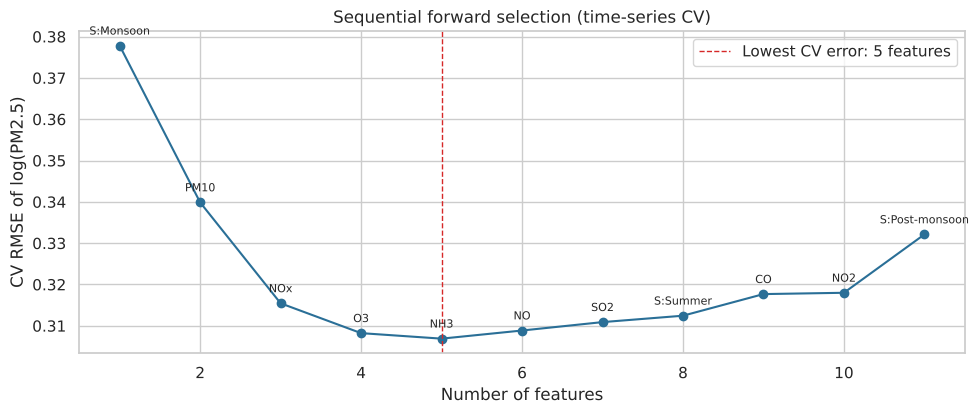

Forward-selected set: ['Season_Monsoon', 'PM10', 'NOx', 'O3', 'NH3']


In [4]:
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(forward.index, forward["TS-CV RMSE (log scale)"], "o-", color="#2a6f97")
for i, r in forward.iterrows():
    ax.annotate(r["feature added"].replace("Season_", "S:"), (i, r["TS-CV RMSE (log scale)"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
best_k = forward["TS-CV RMSE (log scale)"].idxmin()
ax.axvline(best_k, color="#d62828", ls="--", lw=1, label=f"Lowest CV error: {best_k} features")
ax.set(title="Sequential forward selection (time-series CV)", xlabel="Number of features", ylabel="CV RMSE of log(PM2.5)")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "23_forward_selection.png", dpi=150); plt.show()
print("Forward-selected set:", order[:best_k])

# Part B: Ridge and LASSO regression

Both add a penalty to the least-squares loss to shrink the coefficients:

$$\text{Ridge: } \min_\beta \sum (y_i - \mathbf x_i^\top\beta)^2 + \alpha\sum_j \beta_j^2 \qquad\qquad \text{LASSO: } \min_\beta \tfrac{1}{2n}\sum (y_i - \mathbf x_i^\top\beta)^2 + \alpha\sum_j |\beta_j|$$

- **Ridge (L2)** shrinks all coefficients smoothly towards 0. It is the classical remedy for multicollinearity (Unit 2) and lowers variance at the cost of a little bias.
- **LASSO (L1)** can set coefficients **exactly to 0**, so it also selects features.
- Features are **standardised** first, so the penalty treats every variable equally regardless of its units.
- $\alpha$ is chosen by the same 5-fold time-series CV as notebook 05.

In [5]:
alphas_ridge = np.logspace(-3, 4, 80)
alphas_lasso = np.logspace(-5, 0, 80)
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas_ridge, cv=TS, scoring="neg_root_mean_squared_error")).fit(X_tr, y_tr)
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=alphas_lasso, cv=TS, max_iter=50000)).fit(X_tr, y_tr)
ols = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
print(f"Ridge alpha = {ridge[-1].alpha_:.4f}")
print(f"LASSO alpha = {lasso[-1].alpha_:.5f}")

Ridge alpha = 49.6824
LASSO alpha = 0.00393


In [6]:
coefs = pd.DataFrame({
    "OLS": ols[-1].coef_, "Ridge": ridge[-1].coef_, "LASSO": lasso[-1].coef_,
}, index=FEATURES)
coefs["Ridge shrinkage %"] = (1 - coefs.Ridge.abs() / coefs.OLS.abs()) * 100
coefs["LASSO keeps?"] = coefs.LASSO.abs() > 1e-8
coefs.to_csv(TAB / "regularised_coefficients.csv")
coefs.round(4)

,OLS,Ridge,LASSO,Ridge shrinkage %,LASSO keeps?
PM10,0.1663,0.1597,0.1640,3.9533,True
NO,-0.0601,-0.0514,-0.0469,14.4709,True
NO2,0.0566,0.0605,0.0558,-6.7686,True
NOx,0.1354,0.1256,0.1268,7.2286,True
NH3,0.0560,0.0521,0.0506,6.8822,True
CO,-0.0260,-0.0234,-0.0192,10.1742,True
SO2,0.0416,0.0402,0.0372,3.4556,True
O3,0.0714,0.0748,0.0714,-4.8861,True
Season_Summer,-0.0128,-0.0065,-0.0008,49.0850,True
Season_Monsoon,-0.1730,-0.1628,-0.1633,5.9237,True


Coefficients are on the **standardised** scale: the change in log(PM2.5) for a one-standard-deviation rise in the feature. This makes their sizes directly comparable.

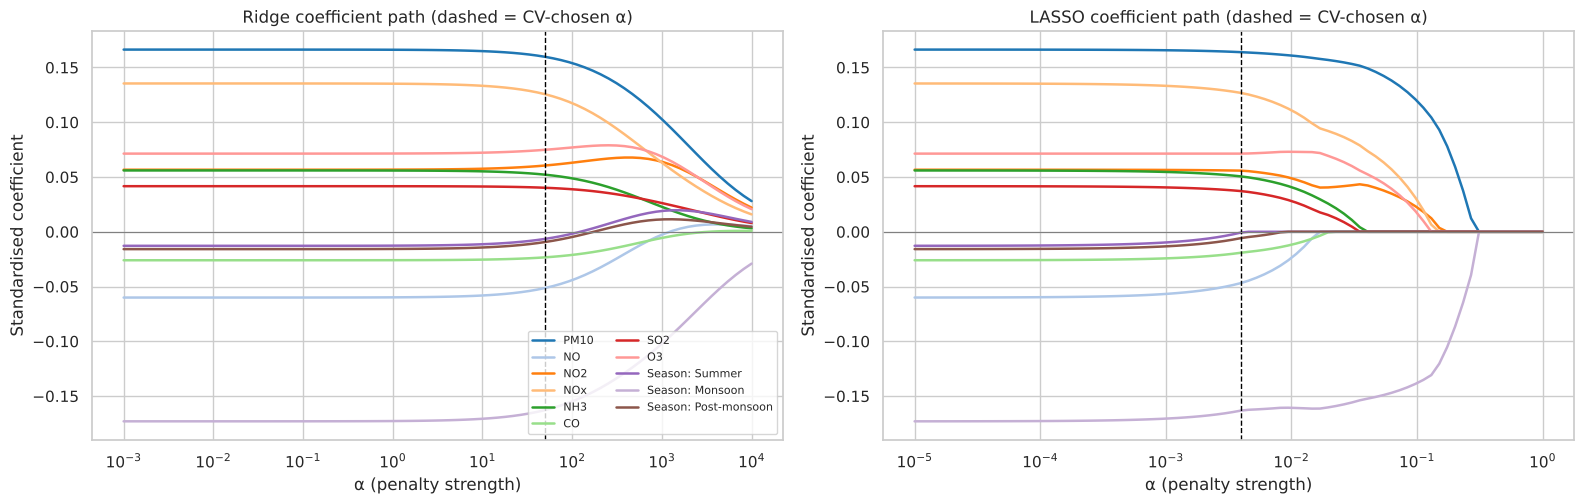

In [7]:
Xs = StandardScaler().fit_transform(X_tr)
ridge_path = np.array([Ridge(alpha=a).fit(Xs, y_tr).coef_ for a in alphas_ridge])
l_alphas, l_coefs, _ = lasso_path(Xs, y_tr.values, alphas=alphas_lasso[::-1])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
pal = sns.color_palette("tab20", len(FEATURES))
for j, f in enumerate(FEATURES):
    axes[0].plot(alphas_ridge, ridge_path[:, j], color=pal[j], lw=1.8, label=f.replace("Season_", "Season: "))
    axes[1].plot(l_alphas, l_coefs[j], color=pal[j], lw=1.8)
axes[0].axvline(ridge[-1].alpha_, color="black", ls="--", lw=1)
axes[1].axvline(lasso[-1].alpha_, color="black", ls="--", lw=1)
for ax, t in zip(axes, ["Ridge coefficient path", "LASSO coefficient path"]):
    ax.set_xscale("log"); ax.axhline(0, color="grey", lw=0.8)
    ax.set(title=t + " (dashed = CV-chosen α)", xlabel="α (penalty strength)", ylabel="Standardised coefficient")
axes[0].legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "24_ridge_lasso_paths.png", dpi=150); plt.show()

In [8]:
# Order in which LASSO drops features as alpha grows = an embedded importance ranking
entry = {}
for j, f in enumerate(FEATURES):
    nz = np.where(np.abs(l_coefs[j]) > 1e-8)[0]
    entry[f] = l_alphas[nz].max() if len(nz) else 0.0
lasso_rank = pd.Series(entry, name="largest α at which the feature is still non-zero").sort_values(ascending=False)
lasso_rank.to_frame()

,largest α at which the feature is still non-zero
PM10,0.2694
Season_Monsoon,0.2694
NO2,0.1504
NOx,0.1300
O3,0.1124
NH3,0.0350
SO2,0.0303
CO,0.0195
NO,0.0146
Season_Post-monsoon,0.0082


The **later** a feature is pushed to zero as α grows, the more important it is. This gives an embedded importance ranking to compare with the filter and wrapper rankings.

## 2. Test-set evaluation

Predictions are back-transformed with the smearing factor from the training residuals, as in notebooks 04-05.

In [9]:
def evaluate(name, model):
    smear = np.mean(np.exp(y_tr - model.predict(X_tr)))
    pred = np.exp(model.predict(X_te)) * smear
    est = model[-1]
    fixed = (Ridge(alpha=est.alpha_) if isinstance(est, RidgeCV) else Lasso(alpha=est.alpha_, max_iter=50000)
             if isinstance(est, LassoCV) else LinearRegression())
    cv = -cross_val_score(make_pipeline(StandardScaler(), fixed), X_tr, y_tr, cv=TS, scoring="neg_root_mean_squared_error").mean()
    return {"model": name, "features used": int(np.sum(np.abs(est.coef_) > 1e-8)),
            "TS-CV RMSE (log)": cv,
            "RMSE_test": np.sqrt(mean_squared_error(y_te, pred)), "MAE_test": mean_absolute_error(y_te, pred),
            "R2_test": r2_score(y_te, pred)}

fs_cols = order[:best_k]
fs_model = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr[fs_cols], y_tr)
def evaluate_subset(name, model, cols):
    smear = np.mean(np.exp(y_tr - model.predict(X_tr[cols])))
    pred = np.exp(model.predict(X_te[cols])) * smear
    cv = -cross_val_score(model, X_tr[cols], y_tr, cv=TS, scoring="neg_root_mean_squared_error").mean()
    return {"model": name, "features used": len(cols), "TS-CV RMSE (log)": cv,
            "RMSE_test": np.sqrt(mean_squared_error(y_te, pred)), "MAE_test": mean_absolute_error(y_te, pred),
            "R2_test": r2_score(y_te, pred)}

reg_results = pd.DataFrame([
    evaluate("OLS (log MLR 2)", ols),
    evaluate(f"Ridge (α = {ridge[-1].alpha_:.3g})", ridge),
    evaluate(f"LASSO (α = {lasso[-1].alpha_:.2g})", lasso),
    evaluate_subset("OLS on forward-selected features", fs_model, fs_cols),
]).set_index("model")
reg_results.to_csv(TAB / "regularisation_results.csv")
reg_results

,features used,TS-CV RMSE (log),RMSE_test,MAE_test,R2_test
model,,,,,
OLS (log MLR 2),11,0.3321,8.0505,6.4767,0.6328
Ridge (α = 49.7),11,0.3283,7.9430,6.3959,0.6425
LASSO (α = 0.0039),11,0.3310,7.9047,6.3755,0.6460
OLS on forward-selected features,5,0.3069,7.5919,6.1425,0.6734


## 3. Summary of feature importance across methods

In [10]:
summary = pd.DataFrame(index=FEATURES)
summary["correlation rank"] = filt["rank (correlation)"]
summary["MI rank"] = filt["rank (MI)"]
summary["forward-selection step"] = [order.index(f) + 1 for f in FEATURES]
summary["LASSO drop-out rank"] = lasso_rank.rank(ascending=False).astype(int)[FEATURES]
summary["kept by LASSO"] = coefs["LASSO keeps?"]
summary["mean rank"] = summary[["correlation rank", "MI rank", "forward-selection step", "LASSO drop-out rank"]].mean(axis=1)
summary = summary.sort_values("mean rank")
summary.to_csv(TAB / "feature_importance_summary.csv")
summary

,correlation rank,MI rank,forward-selection step,LASSO drop-out rank,kept by LASSO,mean rank
Season_Monsoon,1,2,1,1,True,1.2500
PM10,2,1,2,1,True,1.5000
NOx,5,5,3,4,True,4.2500
NO2,3,3,10,3,True,4.7500
O3,4,6,4,5,True,4.7500
NH3,10,4,5,6,True,6.2500
SO2,7,7,7,7,True,7.0000
NO,8,10,6,9,True,8.2500
Season_Summer,6,9,8,11,True,8.5000
CO,11,8,9,8,True,9.0000


## Findings

1. **All methods agree on the top features:** Monsoon (season), PM10 and NOx, followed by O3, NO2 and NH3. CO, Summer and Post-monsoon rank last everywhere, matching the bootstrap result in notebook 05.
2. **Forward selection stops at 5 features** (Monsoon, PM10, NOx, O3, NH3). **Caution:** its CV score is optimistic, because the features were chosen on the same folds that score them. The ranking is therefore read as feature *importance*, not as a definitive subset.
3. On the untouched test period the 5-feature model does well (RMSE 7.59 vs 8.05 for all 11 terms), which suggests the weakest terms add little. AIC, BIC and Cp (notebook 05) preferred all 11 terms; with autocorrelated data, in-sample criteria overstate how much each extra variable helps.
4. **Ridge** (α ≈ 50) shrinks the weak terms most (Summer −49%, Post-monsoon −41%) and barely touches PM10 or Monsoon. It gives a small test gain over OLS (7.94 vs 8.05).
5. **LASSO** at its CV-chosen α keeps all 11 features but shrinks Summer almost to zero; its coefficient path shows the order in which features would be dropped. Its test RMSE is 7.90.
6. Shrinkage helps only a little because multicollinearity is mild (all VIF < 2.5): the gain from regularisation is small, while choosing fewer features (forward selection) helps more.